# Lack of Rodustness of Markowitz Procedure, and the GMV

In [16]:
# Purpose: Load the historical industry returns and estimate the inputs used in the optimisation comparisons.
%load_ext autoreload
%autoreload 2
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import risk_kit as erk

ind = erk.get_ind_returns()
er = erk.annulize_rets(ind["1996":"2000"],12)
cov = ind["1996":"2000"].cov()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
# Purpose: Compute the maximum-Sharpe-ratio allocation for Food and Steel using the historical return estimates.
l = ["Food","Steel"]
erk.msr(0.1,er[l],cov.loc[l,l])

array([0.75040363, 0.24959637])

In [18]:
# Purpose: Inspect the observed returns before testing the effect of small changes in estimated returns.
# These are the observed returns and we did not estimate them but what if we estimate and put.
er[l]

Food     0.116799
Steel    0.115809
dtype: float64

In [19]:
# Purpose: Recalculate the maximum-Sharpe allocation with a first plausible pair of return estimates.
erk.msr(0.1,np.array([.11,.12]),cov.loc[l,l]) # Estimating 11%,12% returns

array([0.57930354, 0.42069646])

In [20]:
# Purpose: Change the estimates slightly to show how sensitive maximum-Sharpe weights can be to input assumptions.
erk.msr(0.1,np.array([.10,.13]),cov.loc[l,l]) # Estimating 10%,13% returns

# As we can see, a very slight change in estimation of percentage returns is causing the portfolio to change heavily.
# Hence not optmimum to use MSR 

array([0., 1.])

<Axes: xlabel='Volatility'>

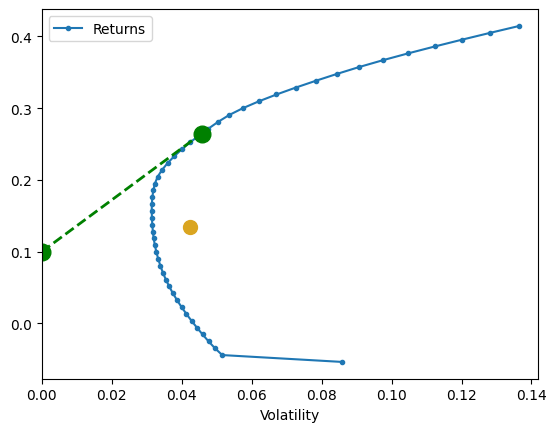

In [21]:
# Purpose: Plot the full frontier with the capital market line and equal-weight portfolio for comparison.
erk.plot_ef(20,er,cov,show_cml=True,riskfree_rate=0.1,show_ew=True)

<Axes: xlabel='Volatility'>

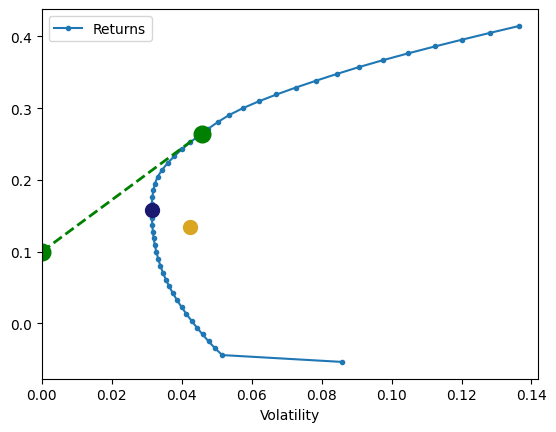

In [22]:
# Purpose: Add the global minimum-variance portfolio, which depends on covariance rather than expected-return estimates.
erk.plot_ef(20,er,cov,show_cml=True,riskfree_rate=0.1,show_ew=True,show_gmv=True)